# Build, Shape, and Extend an OpenClaw Agent on AMD MI300X

---

## What You'll Learn Today

This workshop uses open models served with **vLLM on AMD Instinct MI300X** and
one OpenAI-compatible `vllm-sr/auto` endpoint. You will keep the original
OpenClaw experience while the inference layer selects the appropriate model
and reasoning effort for each turn.

### The Steps

**0. Verify the MI300X inference stack**  
Inspect the vLLM model pool and the routed endpoint.

**1. Meet your agent**  
Start OpenClaw and inspect its persistent workspace and memory.

**2. Give it a task**  
Ask the agent to clone a Python project and set it up.

**3. Fix a bug**  
Have the agent find a bug, trace it, fix it, and verify the result.

**4. Build a review panel**  
Build a coordinator that spawns performance and readability reviewers in
parallel, then merges their findings.

**5. Close the loop with a Fixer**  
Add a Fixer agent that applies the panel's findings and drives verification
to green.

**6. Reveal the routing**  
See which turns used Flash-Next, GLM, or Qwen3.8-27B and compare relative
compute.

### What You'll Walk Away With

- vLLM inference on AMD Instinct MI300X
- one `vllm-sr/auto` endpoint backed by multiple open models
- a personalized OpenClaw agent
- a parallel multi-agent review panel
- a Fixer that turns review findings into verified code


---
## Section 0: MI300X + vLLM Setup

The workshop deployment already serves three models with vLLM:

```text
GPUs 0-3   GLM-5.3-Flash
GPUs 4-5   Qwen3.8-Flash-Next
GPU 6      Qwen3.8-27B
GPU 7      vLLM Semantic Router decision model
```

OpenClaw calls only `vllm-sr/auto`. The router selects a backend for every
request while the agent, tools, memory, and TUI stay unchanged.


In [ ]:
from workshop_lab import lab

runtime_status = lab.check_ready()
lab.clear_routes()


### 🖥️ How the models are served

The models are already running for this lab, so you do not need to launch
another server. The command below is a reference showing the same vLLM serving
pattern used on MI300X.

Open a Jupyter terminal only if you want to inspect the environment.



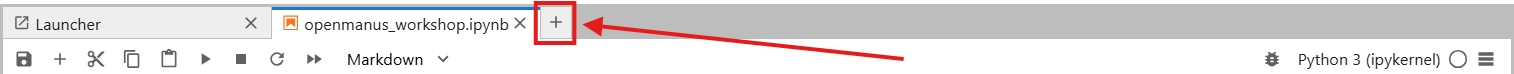

> Find the **terminal icon** in your Jupyter environment (not a notebook cell):

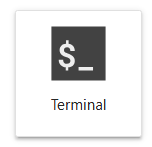

The shared endpoint is backed by independent vLLM servers on MI300X.
For example, the Flash-Next coding backend is served with tensor parallelism
across two GPUs.

The participant workflow uses the routed endpoint rather than starting a
duplicate model process.


```bash
# Reference deployment command — already running for this workshop
vllm serve Qwen/Qwen3.8-Flash-Next-FP8 \
  --served-model-name qwen/qwen3.8-flash-next \
  --host 0.0.0.0 \
  --port 8000 \
  --tensor-parallel-size 2 \
  --max-model-len 131072 \
  --enable-auto-tool-choice \
  --tool-call-parser qwen3_xml \
  --reasoning-parser qwen3
```

The GLM and Qwen3.8-27B backends use the same OpenAI-compatible vLLM API.
vLLM Semantic Router exposes all three as one virtual model:
`vllm-sr/auto`.


In [ ]:
import os

print("READY - workshop runtime and routed endpoint are available")
print("OpenClaw model:", lab.auto_model)
print("Endpoint: secret-safe local proxy to vllm-sr/auto")
print("Dashboard:", os.getenv("VLLM_SR_DASHBOARD_URL", "configured by presenter"))


You should see a ready runtime, `vllm-sr/auto`, and the Dashboard URL.
No endpoint key is printed or stored in the notebook.


---
## Section 1: Meet your OpenClaw agent

OpenClaw is installed and preconfigured against the routed vLLM endpoint.
The next cell verifies that `main` uses `vllm-sr/auto`.

This is still ordinary OpenClaw: the endpoint optimization is entirely below
the agent layer.


In [ ]:
import json

agents = json.loads(
    lab.openclaw_command("agents", "list", "--json").stdout
)
main_agent = next(row for row in agents if row["id"] == "main")
print("Agent:", main_agent["id"])
print("Workspace:", main_agent["workspace"])
print("Model:", main_agent["model"])


### Start the Gateway

The Gateway runs the agent and connects the TUI to the routed vLLM endpoint.
Keep one Gateway and one TUI lifecycle for the workshop.


In [ ]:
gateway_pid = lab.start_gateway()
print("Gateway ready. PID:", gateway_pid)


### 🖥️ Meet your agent in the TUI

Open a **new terminal** (`+` → Terminal) and run:

```bash
openclaw tui
```

### 🦞 Meet your OpenClaw agent

Once the TUI connects, say:

```text
Hi
```

On a fresh workspace, OpenClaw starts a short first-run conversation. Answer
its questions until it chooses an identity and confirms that setup is complete.
That conversation personalizes `IDENTITY.md`, `SOUL.md`, and `USER.md`.

Keep the TUI open. This is where you will interact with your agents for the
rest of the lab.


### 👀 Behind the scenes: what just happened?

OpenClaw persists identity, policy, user context, and memory as files in each
agent's workspace. In this environment the main workspace is:

```text
/workspace/agents/main/
├── SOUL.md
├── AGENTS.md
├── IDENTITY.md
├── USER.md
├── TOOLS.md
├── HEARTBEAT.md
├── BOOTSTRAP.md  ← first-run ritual; removed after setup
└── memory/
```

**SOUL.md is personality. AGENTS.md is operating policy.** After completing
the first-run conversation in the TUI, run the next cell to inspect the
files OpenClaw now reads on every turn.


In [ ]:
workspace = lab.agents / "main"

required = ["IDENTITY.md", "SOUL.md", "AGENTS.md"]
missing = [name for name in required if not (workspace / name).is_file()]
if missing:
    raise RuntimeError(
        "OpenClaw workspace setup is incomplete; missing: "
        + ", ".join(missing)
        + ". Ask the host to run workshop-reset, then start the TUI again."
    )

if (workspace / "BOOTSTRAP.md").exists():
    print("FIRST-RUN SETUP IS STILL ACTIVE")
    print("Finish the short identity conversation in the TUI, then rerun this cell.\n")

for filename in required:
    path = workspace / filename
    print("=" * 60)
    print(filename)
    print("=" * 60)
    text = path.read_text()
    print(text[:2000] + ("\n... (truncated)" if len(text) > 2000 else ""))
    print()


---
## Section 2: Pull the App

Now let's give the agent something to work with. Ask the agent to clone the typing app and set it up.

### 🦞 Ask your OpenClaw agent
Ask your OpenClaw agent to clone the `Mahdi-CV/open_type_faster` repo and explain it to you. Here is an example:

```text
"Clone https://github.com/Mahdi-CV/open_type_faster install its dependencies, and tell me how to run it"
```

Your agent uses shell tools to clone the repo, inspect its requirements, and install the libraries. It doesn't just answer, it runs the commands for you.

---
## Section 3: Fix a bug

### Step 1 - Spot the bug yourself

#### 🖥️ Open a new terminal and run the app

In a new terminal, follow the instructions OpenClaw provides on how to run `open_type_faster`.

Type for 30 seconds. When the results screen appears, look at the accuracy.

> **Something is off. Do you see it?**

### Step 2 - Ask OpenClaw to test

#### 🦞 Ask your OpenClaw agent

Ask your OpenClaw agent to fix the bug. Here is an example:

```text
"There seems to be an accuracy bug in this open_type_faster app, can you help identify and fix?"
```

---
## Note: Adding Skills

What the agent just did, finding and fixing bugs, doesn't have to be a one-off. You can package that behavior into a reusable **skill** that works on any Python project.

Skills live in directories containing `SKILL.md` files. OpenClaw discovers eligible skills and injects a compact list of their names, descriptions, and locations into the agent's system prompt. When the agent decides a skill is relevant, it reads that skill's SKILL.md and follows its instructions. 

You can create your own skills by asking your agent to write one, or explore the growing ecosystem of community-contributed skills at **[clawhub.ai](https://clawhub.ai)**.

---
## Section 4: Build a review panel (multi-agent)

You've built one agent that works on its own, but real teams don't ship on one person's say-so. Before code merges, you'd want multiple people to review changes. Let's build that panel.

You'll create a **coordinator** and two **specialist reviewers**. The coordinator hands the same file to both at once, each reviews it through its own lens, and the coordinator merges their findings into one report.

| Agent | Job |
|---|---|
| 🧭 **main** (coordinator) | Spawns the two reviewers in parallel and merges their reports into one review |
| ⚡ **performance** | Flags obvious inefficiencies: repeated work in loops, O(n²) patterns, needless re-computation |
| 📖 **readability** | Flags unclear names, dead code, long functions, anything that hurts maintainability |

Each reviewer is its own agent with one narrow focus. That's the whole idea of a multi-agent system: split the work by specialty, run it in parallel, and combine the results.

<p align="center"></p>

The orchestrator spawns two reviewer agents in parallel, then calls `sessions_yield` to wait until both finish. Each reviewer works in its own isolated session and writes its findings to a file in `/tmp/panel/`. Once both files exist, `main` wakes, reads them, and merges the two into one final report that lands in its own context, grouped by Performance and Readability.


### Step 1: Add the reviewer agents

A specialist reviewer is just another OpenClaw agent with its own workspace.
You add one with a single reusable command:

```bash
openclaw agents add <name> --non-interactive --workspace /workspace/agents/<name>
```

- `<name>` is how you refer to the agent and how `main` spawns it.
- `--workspace` isolates that agent's identity, memory, and operating rules.
- The new agent inherits the configured `vllm-sr/auto` endpoint.
- Removing its `BOOTSTRAP.md` skips the personal onboarding ritual for a
  focused worker agent.

- `performance` reviews computational efficiency.
- `readability` reviews maintainability.

> 💡 Remember the `openclaw agents add` pattern. You will use the same
> command to add your **Fixer** agent in the challenge.

Run the next cell to add both reviewers. The existence checks only make the
cell safe to run twice; the two `openclaw agents add` lines are the important
part.


In [ ]:
%%bash
set -euo pipefail
ROOT="${OPENCLAW_WORKSHOP_WORKSPACES:-/workspace/agents}"

# Reusable pattern:
# openclaw agents add <name> --non-interactive --workspace "$ROOT/<name>"

if ! openclaw agents list --json | jq -e 'any(.id == "performance")' >/dev/null; then
  openclaw agents add performance --non-interactive --workspace "$ROOT/performance"
else
  echo "performance already exists"
fi
rm -f "$ROOT/performance/BOOTSTRAP.md"

if ! openclaw agents list --json | jq -e 'any(.id == "readability")' >/dev/null; then
  openclaw agents add readability --non-interactive --workspace "$ROOT/readability"
else
  echo "readability already exists"
fi
rm -f "$ROOT/readability/BOOTSTRAP.md"

echo "Created agents: performance, readability"


### Step 2: Let `main` spawn the reviewers

Creating reviewers is not enough. `main` needs explicit authority to spawn
them and access the spawn/yield tools.

OpenClaw 2.0 applies higher-risk spawn authority at the coordinator agent
scope, so both settings below are authored directly on `main`.


In [ ]:
%%bash
openclaw config set \
  agents.entries.main.subagents.allowAgents \
  '["performance","readability"]' \
  --strict-json

openclaw config set \
  agents.entries.main.tools.alsoAllow \
  '["sessions_spawn","sessions_yield","subagents"]' \
  --strict-json

echo "main can now spawn: performance, readability"


### Step 3: Teach main how to run the panel

Right now `main` knows it *can* spawn the reviewers, but not *how* to run a review. We'll give it a reusable **Review Panel Protocol**: find the file, spawn both reviewers, then merge their findings.

The trick that makes this reliable across asynchronous agent turns is a simple **file rendezvous**. Each reviewer writes its findings to a fixed file (`/tmp/panel/performance.md`, `/tmp/panel/readability.md`). The coordinator spawns both, yields, and each time it wakes it just checks *how many of those two files exist*. When both are present it reads them and merges. The coordinator never has to hold review text in its head across turns, so it can't lose track and stall. The files are the single source of truth.

> 💡 The reviewers run in parallel as sub-agents. The coordinator waits with `sessions_yield` and is woken by a completion event when each one finishes.

Because this is an operating rule (not personality), it belongs in **AGENTS.md**, the agent's standard operating procedure. Personality and tone go in `SOUL.md`; rules go in `AGENTS.md`. The next cell appends the protocol to `main`'s AGENTS.md, once.


In [ ]:
%%bash
# Append the Review Panel Protocol to main's AGENTS.md (its operating manual), once
AGENTS="${OPENCLAW_WORKSHOP_WORKSPACES:-/workspace/agents}/main/AGENTS.md"
if ! grep -q "Review Panel Protocol" "$AGENTS" 2>/dev/null; then
cat >> "$AGENTS" << 'EOF'

## Review Panel Protocol

You coordinate two reviewer agents: "performance" and "readability". You review
NOTHING yourself. Reviewing the file inline is a FAILURE.

Each reviewer writes its findings to a file:
- performance -> /tmp/panel/performance.md
- readability -> /tmp/panel/readability.md

You do NOT need to remember review text between turns. The files are the source
of truth. Every time you wake up, just check which files exist.

When the user asks you to "run the review panel" on a repo URL or a file path:

1. Resolve the target to a full file path. If given a repo URL, clone it into your
   workspace with exec and locate the target source file. If given a file path,
   use it as-is.

2. Prepare the output folder with exec:
     mkdir -p /tmp/panel && rm -f /tmp/panel/performance.md /tmp/panel/readability.md

3. Spawn BOTH reviewers back to back, then yield once:
   a. Call sessions_spawn:
        agentId: "performance"
        context: "isolated"
        task: "Review <full path> for performance issues. Write findings to /tmp/panel/performance.md and reply with them."
   b. Call sessions_spawn:
        agentId: "readability"
        context: "isolated"
        task: "Review <full path> for readability issues. Write findings to /tmp/panel/readability.md and reply with them."
   c. Call sessions_yield with no parameters.

4. A completion event will wake you when a reviewer finishes. On EVERY wake, do
   exactly this:
   a. Run exec: ls /tmp/panel/performance.md /tmp/panel/readability.md 2>/dev/null | wc -l
   b. If the count is 2 (both files exist), go to step 5 and MERGE.
   c. If the count is less than 2, call sessions_yield again with no parameters to
      wait for the other reviewer. Do not reply to the user yet.

5. MERGE (only when both files exist):
   a. Run exec: cat /tmp/panel/performance.md and exec: cat /tmp/panel/readability.md
   b. Write ONE merged reply with a "Performance" section (the performance file
      contents) and a "Readability" section (the readability file contents).
      Output it directly to the user. You are done. Do NOT yield again.

Rules:
- context MUST be "isolated" ("fork" will error across different agents).
- Spawn both reviewers before the first yield. Never review anything yourself.
- The files are the source of truth. Never say you are "still waiting" for a
  review whose file already exists. Once both files exist, merge and finish.
EOF
  echo "Review Panel Protocol added to main AGENTS.md"
else
  echo "Review Panel Protocol already present in main AGENTS.md"
fi


### Step 4: Restart the gateway

The gateway reads its agents and workspace files fresh when it starts, so a restart is the surest way to load your new reviewers and the protocol you just added. The next cell stops the running gateway and launches it again in the background.

In [ ]:
lab.stop_gateway()
gateway_pid = lab.start_gateway()
print("Gateway restarted. PID:", gateway_pid)


### Step 5: Brief each reviewer, in your agent chat

The restart in Step 4 makes your earlier TUI session stale (that's the `session file changed` error if you keep using it), so start a **fresh session** first. If your TUI is still open, type `/exit` (or press Ctrl-C), then relaunch it:

```bash
openclaw tui
```

A fresh session reconnects to the restarted gateway and loads the new reviewers and Review Panel Protocol. You'll do everything from here: brief the reviewers, then run the panel.

A sub-agent only reads its own `AGENTS.md`, so give each reviewer its job once and have it save the rules. For each agent, switch to it with `/agent <name>`, send its brief, then move to the next.

#### **1. ⚡ performance**:
##### 🦞 Ask your Performance Agent
Type 
```bash
/agent performance
```
then send:

```text
"You are the Performance reviewer. When given a file path, read that file and report ONLY performance issues: repeated work inside loops, O(n^2) patterns, redundant computation, and needless allocations. For each issue give: file:line, why it's slow, and a one-line fix. If you find nothing, say "No performance issues found." Always save your complete findings to /tmp/panel/performance.md before you reply, then reply with them too. Save these rules to your AGENTS.md."
```

#### **2. 📖 readability**: 
##### 🦞 Ask your Readability Agent
Type 
```bash
/agent readability
```
then send:

```text
"You are the Readability reviewer. When given a file path, read that file and report ONLY readability and maintainability issues: unclear names, dead code, long functions, missing structure. For each issue give: file:line, the problem, and a one-line suggestion. If you find nothing, say "No readability issues found." Always save your complete findings to /tmp/panel/readability.md before you reply, then reply with them too. Save these rules to your AGENTS.md."
```

#### **3. Switch back**
##### 🦞 Switch back to your main OpenClaw agent
Type 
```bash
/agent main
```
to switch back to the coordinator. You're ready to run the panel.


### Step 6: Run the review panel

Back in your agent chat, make sure you're on your **main** agent (type `/agent main` if not). Your main agent already knows how to run the panel, you taught it the **Review Panel Protocol** in its AGENTS.md during setup, so the ask is now a single line.

We'll point it at a small sales-report script that runs fine but was written in a hurry, it's slow and messy, so both reviewers have plenty to find.

> ⏱️ The coordinator spawns both reviewers, waits while they work in parallel, then merges what they wrote. Each reviewer works in its own session, through its own lens.

#### 🦞 Clear your chat
Type
```bash 
/reset
```
in your agent chat before you run the panel. It clears main's conversation so the coordinator starts from a clean context. The panel spawns two sub-agents and waits for both, and a long history carried over from the earlier steps can make it crawl.

#### 🦞 Ask your main OpenClaw agent

```text
"Run the review panel on https://github.com/Mahdi-CV/sloppy-sales (the file to review is report.py)."
```

Because the orchestration lives in the agent's AGENTS.md, that one line is enough: it clones the repo, finds `report.py`, spawns both reviewers, each of which writes its findings to `/tmp/panel/`, then merges their findings into one review grouped by Performance / Readability.

> 💡 Point it at any repo or file: `Run the review panel on <path>`. Same protocol, no re-briefing needed.

### 👀 What just happened

Each reviewer ran as its own agent, in its own session, on the same file. The coordinator spawned both, waited while they worked in parallel, and each reviewer wrote its findings to a file in `/tmp/panel/`. When both files were present, the coordinator read them and merged both into a single review grouped by Performance / Readability.

That file rendezvous is the trick: the coordinator never has to remember review text across turns, it just checks which files exist and merges once both are there. No lost results, no stalling.

You didn't write any orchestration code. You created two focused agents and gave one coordinator permission to spawn them. That is a multi-agent system: specialization plus delegation.

### Routing summary so far

The panel is still the same OpenClaw workflow. Instead of printing every
request, the next cell gives one final summary: **Total routed LLM calls**, each
model's call share, dynamic reasoning effort, and relative compute.

The comparison asks: **What if every observed call had used GLM-5.3-Flash at
max reasoning?** To keep it reproducible, the baseline uses the exact same
observed token volume at the recipe's all-GLM-5.3-Flash relative-compute
rate. It is
conservative because it does not add extra tokens that max reasoning might
have generated.


In [ ]:
panel_summary = lab.show_routing_summary(
    source="live",
    title="OpenClaw traffic before the Fixer challenge",
)


---
## Section 5: The Challenge, close the loop with a Fixer

So far your panel only *advises*, it finds problems but a human still fixes them. Time to make it act. You'll add a **third agent, a Fixer**, that takes the reviewers' findings, applies them, and drives the code to green. That turns your two-agent panel into a full three-agent system that reviews, fixes, and verifies on its own.

There's a small buggy repo waiting at `https://github.com/Mahdi-CV/catch-the-bug.git`. It has a few real behavior bugs **and** some genuinely messy code planted for your reviewers to catch.

### The system you're building

<p align="center"></p>

The reviewers never talk to each other. They hand their findings to `main` through two files in `/tmp/panel/`, `main` merges them, then passes them to the Fixer. Those files are the shared bus between agents

In [ ]:
%%bash
# Start from a clean slate: clear any reviews left over from Section 6 so the
# panel and the Fixer only ever see this challenge's findings.
rm -f /tmp/panel/performance.md /tmp/panel/readability.md
echo "cleared /tmp/panel, everyone starts clean"


### 🦞 Clear your chat
Type
```bash 
/reset
```
in your agent chat before you continue. It clears main's conversation so the coordinator starts from a clean context.

### Your mission, in three steps

1. **Add and brief a Fixer agent.** Grow the panel from two agents to three, and let `main` spawn it.
2. **Run the loop.** Have the panel review `typing_stats.py`, then hand its findings to the Fixer to apply. Keep the merged review, you'll show it.
3. **Qualify.** Run `verify.py` and clear both gates to earn your completion code.

Try each step yourself first, you've already seen every piece in Section 6. Stuck? Open the matching hint.

<details>
<summary>💡 Hint 1, add and brief the Fixer</summary>

A Fixer is just another agent, nothing new here:

1. **Add the agent** the same way you added the reviewers in Step 1 (the `openclaw agents add ... --workspace ...` command, then delete its `BOOTSTRAP.md`).
2. **Let `main` spawn it** by adding `fixer` to the spawn allow-list you set in Step 2 (`agents.defaults.subagents.allowAgents`, now with three names).
3. **Reload the gateway** so it picks up the new agent and allow-list: run the **Reload the gateway** cell just below these hints.

Then open a fresh TUI, switch to it with `/agent fixer`, and **write your own brief**. There's no fixed script, but a good brief hits these points:

- its one job: apply the reviewers' findings and make the failing tests pass
- where the findings live: the panel writes them to `/tmp/panel/performance.md` and `/tmp/panel/readability.md`
- keep edits minimal, and only to the file under review
- never touch anything under `tests/` or the verification script
- after editing, re-run the tests to confirm they pass

End the brief by asking it to save those rules to its `AGENTS.md` so they stick, then switch back with `/agent main`.

</details>

<details>
<summary>💡 Hint 2, run the review, then hand off to the Fixer</summary>

Drive it in two one-line asks. One job per turn keeps each agent focused and reliable:

```text
"Run the review panel on https://github.com/Mahdi-CV/catch-the-bug (the file to review is typing_stats.py)."
```

When the merged review comes back:

```text
"Now spawn the fixer on the typing_stats.py you just reviewed so it applies the panel's findings and gets the tests green."
```

If `main` won't reliably spawn the Fixer from that plain ask, teach it a recipe, exactly like the Review Panel Protocol you added in Step 3. Add a short **Fixer Handoff Protocol** to main's `AGENTS.md` that spells out, in order, what it should do when you ask it to run the fixer:

- work out the full path of the file that was just reviewed
- `sessions_spawn` the `fixer` with `context: "isolated"` and a task that points it at the two `/tmp/panel/*.md` files and that file path
- `sessions_yield` to wait while the fixer works
- when the fixer wakes it, relay the report and do not yield again

Because you changed main's `AGENTS.md`, run the **Reload the gateway** cell below again so main loads the new protocol.

</details>

<details>
<summary>💡 Hint 3, qualify</summary>

Let your agent close the loop. From `main`, ask it to run the qualifier inside the cloned repo and report back:

```text
"In the catch-the-bug repo, install requirements and run verify.py, then show me exactly what it prints."
```

That runs the two-gate check for you:

```bash
pip install -r requirements.txt
python verify.py
```

`verify.py` has two gates: the behavior tests must pass, **and** the perf/readability issues the reviewers flagged must actually be gone. If it reports findings still remain, it names them, send the Fixer back with that specific list. When both gates pass it prints your completion code. Show that code **plus your panel's review output** to a workshop host to claim your gift. 🎁

> Do not edit the tests or `verify.py`. Fix the module, not the checks. Correct behavior is defined by the tests in `tests/`.

</details>

### Reload the gateway

Run this whenever you change something the gateway loads at startup: the spawn allow-list in **Hint 1**, or main's `AGENTS.md` in **Hint 2**. Running it when nothing changed is harmless, it just guarantees your latest edits are picked up.

In [ ]:
lab.stop_gateway()
gateway_pid = lab.start_gateway()
print("Gateway restarted. PID:", gateway_pid)


### The goal

A three-agent system you built, powered by vLLM on AMD Instinct MI300X: two reviewers that flag the problems in a repo they've never seen, and a Fixer that acts on their findings and drives the code until `verify.py` goes green and hands you a completion code. Review, fix, verify, with no human in the loop.

> 💡 Keep each agent's brief to ONE job. The panel works because every agent has a narrow, clear focus. The reviewers find, the Fixer acts. Don't let the Fixer freelance, it should apply what the reviewers surfaced.


## Your Mission

Add a Fixer agent, point your three-agent panel at `catch-the-bug`, let the reviewers flag the issues and the Fixer apply them, and get `verify.py` to green. Show your completion code and your panel's review to claim your gift, all through vLLM on AMD Instinct MI300X. 🔬🦞🎁

---
## Section 6: What vLLM Semantic Router changed

OpenClaw always called one endpoint. The recipe used:

```text
code_agentic → Qwen3.8-Flash-Next
agentic      → GLM-5.3-Flash
recovery     → GLM-5.3-Flash
fast         → Qwen3.8-27B, reasoning off
```

The agent team, prompts, tools, and file rendezvous did not change.


In [ ]:
workshop_summary = lab.show_routing_summary(
    source="live",
    title="Final OpenClaw workshop routing summary",
)


The summary answers the two audience questions directly:

1. Out of all routed LLM calls, how many went to each physical model?
2. How much relative compute did `vllm-sr/auto` avoid versus sending the
   same observed workload to GLM-5.3-Flash at max reasoning?

`XXX` is relative compute, not money. Keep the vLLM-SR Dashboard Insights
view open beside this notebook when you want to drill into individual calls.
